# Guided Release Timeline — MusicBrainz Official Releases
_How the official catalog grew, which release types dominate, and where the country tag points_

***

**Programming Language:** Python in the Jupyter Notebook Environment

**Dataset:** [kaitoland/artist-release-timeline](https://www.kaggle.com/datasets/kaitoland/artist-release-timeline)

**Style counterpart:** [Guided Numeric and Text Exploration — E-Commerce](https://www.kaggle.com/code/nicapotato/guided-numeric-and-text-exploration-e-commerce)

**Code Navigation:** <br>
In the code, text after hashtags (`#`) are supportive explanations, not executed as code.

***

# Tables of Content:

**1. [Introduction](#Introduction)** <br>
**2. [Setup and Data Peek](#Setup)** <br>
**3. [Univariate Distributions](#Univariate)** <br>
**4. [The Catalog Over Time](#Growth)** <br>
**5. [Who and Where](#Who)** <br>
**6. [What Describes the Growth](#Model)** <br>
**7. [What It Means — Working Synthesis](#Synthesis)** <br>

# **1. Introduction:** <a id="Introduction"></a> <br>
Each row is one official MusicBrainz release from the fullexport dated 20261024. The file holds 5,328,728 releases and 917,257 artist MBIDs. The artist key is `artist_mbid`. Display names are fewer (847,439), and one name can sit on more than one MBID, so the charts group by MBID.

Blank year, month, release type, and country stay blank. Numeric years run from 206 through 3036. The charts use the window 1950–2026, which holds 5,101,009 releases. 2026 is a partial year because the dump ends on 24 October 2026, so the growth fit stops at 2025.

The question is how that official catalog grew, which release types took the share, and which country codes the releases carry. Various Artists is a bucket. Bach, Beethoven, and Mozart sit high because many official editions share one composer MBID.

# **2. Setup and Data Peek:** <a id="Setup"></a>

In [1]:
# General
import numpy as np
import pandas as pd
from pathlib import Path

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# Scientific / modeling helpers
from IPython.display import display
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

import kagglehub

# Set Plot Theme (same family as the guided series)
sns.set_theme(style="whitegrid")
PALETTE = ["#30a2da", "#fc4f30", "#e5ae38", "#6d904f", "#8b8b8b"]
sns.set_palette(PALETTE)
plt.rcParams["figure.figsize"] = (11, 5)

# Warnings
import warnings
warnings.filterwarnings("ignore")

# Wide table inspection in Jupyter cell outputs
pd.set_option("display.max_columns", 999)
pd.set_option("display.width", 220)


def park_legend(ax, title=""):
    ax.legend(
        title=title,
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        borderaxespad=0,
        frameon=False,
    )

**Code Explanation and Reasoning:** <br>
These packages fall into three buckets: *General*, *Visualization*, and *Scientific / modeling helpers*.

`pandas` / `numpy` hold the table; `matplotlib` / `seaborn` do the graphics; `scipy` ranks associations; `sklearn` fits one linear model on a hold-out split (`random_state=7`). `kagglehub` resolves the file both on Kaggle (`/kaggle/input/...`) and locally.

The five-color palette matches the guided series so sequential plots feel like one exploration. When a plot has a legend, `park_legend` places it to the right of the axes.

In [2]:
KAGGLE_SLUG = "kaitoland/artist-release-timeline"
CSV_NAME = "official_releases.csv"
USECOLS = [
    "artist_mbid",
    "artist_name",
    "date_year",
    "date_month",
    "release_group_type",
    "country_code",
]


def resolve_file(basename: str, slug: str = KAGGLE_SLUG) -> Path:
    kaggle_root = Path("/kaggle/input")
    if kaggle_root.exists():
        for p in kaggle_root.rglob(basename):
            return p
    local_data = Path("data") / basename
    if local_data.exists():
        return local_data
    path = Path(kagglehub.dataset_download(slug))
    found = path / basename
    assert found.exists(), f"expected {basename} under {path}"
    return found


csv_path = resolve_file(CSV_NAME)
header = pd.read_csv(csv_path, nrows=0)
assert set(USECOLS) <= set(header.columns)
df = pd.read_csv(csv_path, usecols=USECOLS, low_memory=False)
print("CSV:", csv_path)
print("Dataframe Dimension:", df.shape[0], "Rows,", df.shape[1], "Columns")
assert df.shape == (5328728, 6)
assert df.artist_mbid.nunique() == 917257
assert df.artist_name.nunique(dropna=True) == 847439
print("Artist MBIDs:", df.artist_mbid.nunique())
print("Artist names (non-blank):", df.artist_name.nunique(dropna=True))
print("Blank artist names:", int(df.artist_name.isna().sum()))

CSV: /kaggle/input/datasets/kaitoland/artist-release-timeline/official_releases.csv
Dataframe Dimension: 5328728 Rows, 6 Columns
Artist MBIDs: 917257
Artist names (non-blank): 847439
Blank artist names: 50


**Code Explanation and Reasoning:** <br>
The loader keeps six columns. Title, release MBID, and day are outside this question, and the full CSV is hundreds of megabytes. On Kaggle the file is found under `/kaggle/input`. Locally, `data/official_releases.csv` wins if it exists; otherwise `kagglehub` downloads the dataset.

The asserts lock the published grain: 5,328,728 official releases, 917,257 artist MBIDs, 847,439 non-blank names.

In [3]:
print("Column Data Types:")
print(df.dtypes.to_string())
print()
print("Null counts:")
print(df.isna().sum().to_string())
display(df.sample(5, random_state=7))

df["year"] = pd.to_numeric(df.date_year, errors="coerce")
print("Year blank:", int(df.year.isna().sum()))
print("Year min / max:", df.year.min(), "/", df.year.max())
print("Year < 1900:", int((df.year < 1900).sum()))
print("Year > 2026:", int((df.year > 2026).sum()))
assert int(df.year.isna().sum()) == 204391
assert df.year.min() == 206
assert df.year.max() == 3036

window = df.loc[df.year.between(1950, 2026)].copy()
window["year"] = window.year.astype(int)
window["type_label"] = window.release_group_type.fillna("(blank)")
window["country_label"] = window.country_code.fillna("(blank)")
assert len(window) == 5101009
print("Window 1950-2026:", len(window))
print("2026 releases (partial year):", int((window.year == 2026).sum()))
print("2024 releases:", int((window.year == 2024).sum()))
assert int((window.year == 2024).sum()) == 259121
assert int((window.year == 2026).sum()) == 154694

Column Data Types:
artist_mbid            object
artist_name            object
date_year             float64
date_month            float64
release_group_type     object
country_code           object

Null counts:
artist_mbid                 0
artist_name                50
date_year              204391
date_month            1527252
release_group_type      56166
country_code           614668


,artist_mbid,artist_name,date_year,date_month,release_group_type,country_code
516402,c136759e-c98e-4dc0-b5d2-1922943da8a2,Dana Winner,1996.0,NaN,Album,BE
3287581,ef8f208b-bb0d-4b68-8ffb-3701a2bea39f,Kyper,2011.0,10.0,Album,XW
2158407,be547bca-8718-4762-bf1b-34a3bdb4938f,AKB48,2014.0,8.0,Single,JP
1491404,d93e27a5-7317-4239-a7b6-9ddfc461b946,Thane Russal & Three,1966.0,3.0,Single,GB
342176,6b1bef06-ec88-4327-9dd4-79773aa7264e,A Different Dimension,2006.0,4.0,Single,US


Year blank: 204391
Year min / max: 206.0 / 3036.0
Year < 1900: 1268
Year > 2026: 244
Window 1950-2026: 5101009
2026 releases (partial year): 154694
2024 releases: 259121


**Interpretation:** <br>
204,391 releases have a blank year, and that blank stays blank. Another 1,268 dated releases fall before 1900, and 244 fall after 2026, including year 3036. Those rows remain in the file and stay outside the 1950–2026 window. Inside the window, 2024 is the busiest year (259,121 official releases) and 2026 is shorter (154,694) because the export stops on 24 October 2026. Month is blank on a large share of rows and is left blank; the charts use year.

# **3. Univariate Distributions:** <a id="Univariate"></a>

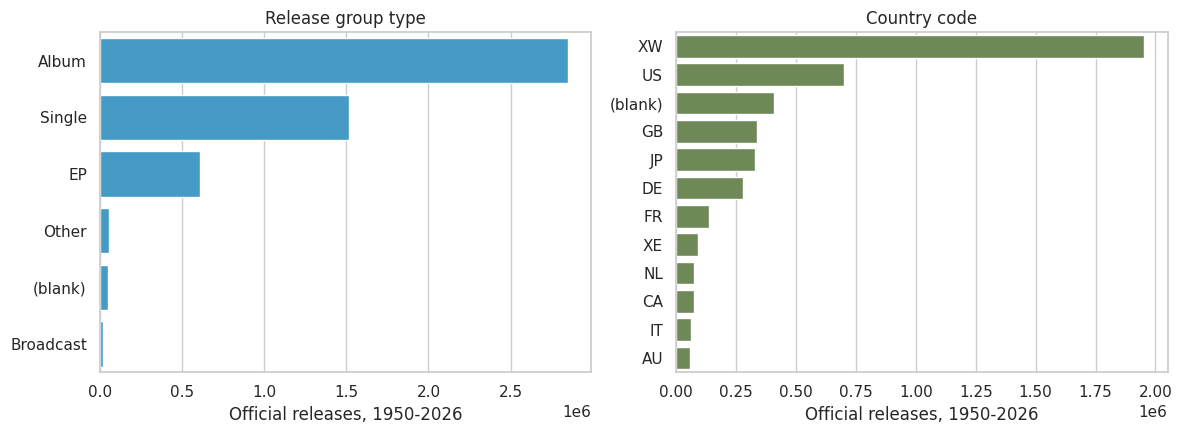

type_label
Album        2850111
Single       1515877
EP            611619
Other          52395
(blank)        50271
Broadcast      20736
Month blank in the window: 25.6%


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
type_counts = window.type_label.value_counts()
sns.barplot(x=type_counts.values, y=type_counts.index, ax=axes[0], color=PALETTE[0])
axes[0].set_xlabel("Official releases, 1950-2026")
axes[0].set_ylabel("")
axes[0].set_title("Release group type")

top_countries = window.country_label.value_counts().head(12)
sns.barplot(x=top_countries.values, y=top_countries.index, ax=axes[1], color=PALETTE[3])
axes[1].set_xlabel("Official releases, 1950-2026")
axes[1].set_ylabel("")
axes[1].set_title("Country code")
fig.tight_layout()
plt.show()
print(type_counts.to_string())
print("Month blank in the window:", f"{window.date_month.isna().mean():.1%}")

**Interpretation:** <br>
Album, Single, and EP are the three large types. The `(blank)` bar is the missing release-group type, left missing on the frame and labeled only on this chart. `XW` is MusicBrainz's worldwide code and it leads the country list, ahead of US, a blank country, GB, JP, and DE. `XE` is the Europe code. A blank country stays blank.

# **4. The Catalog Over Time:** <a id="Growth"></a>

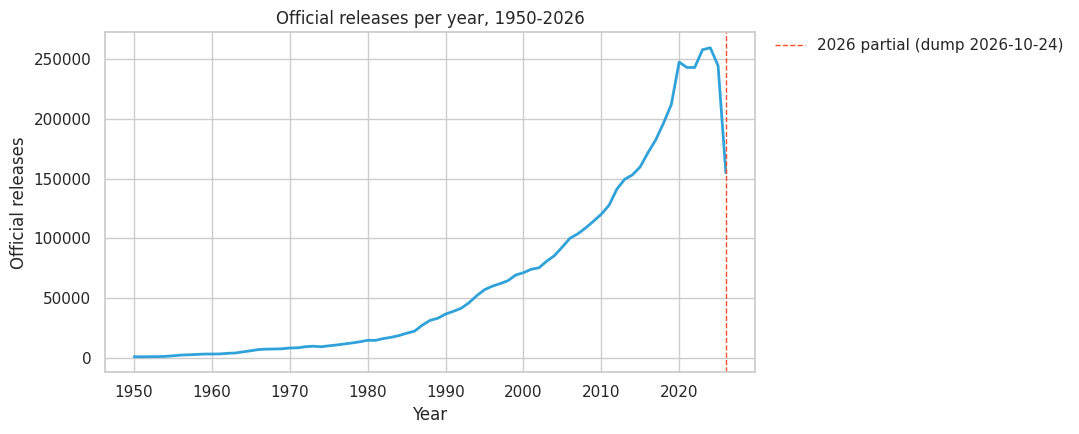

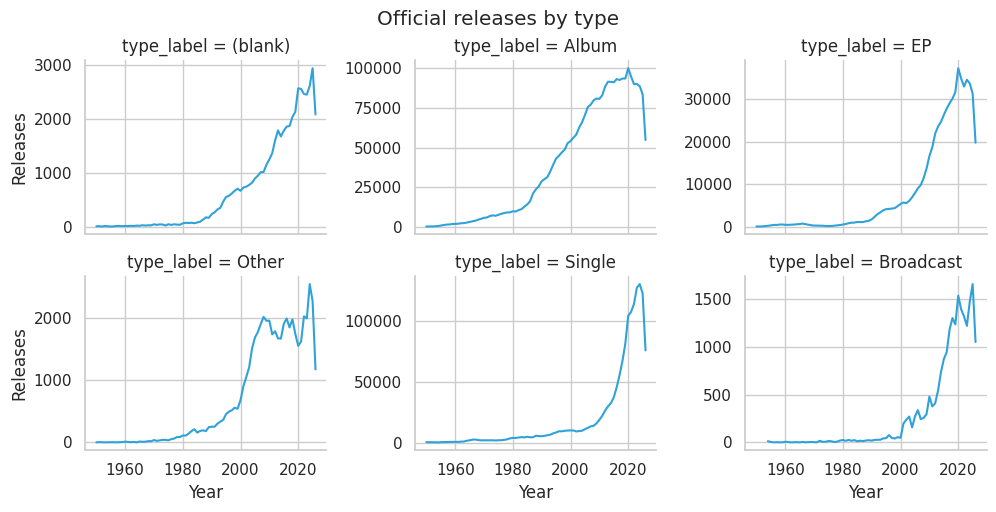

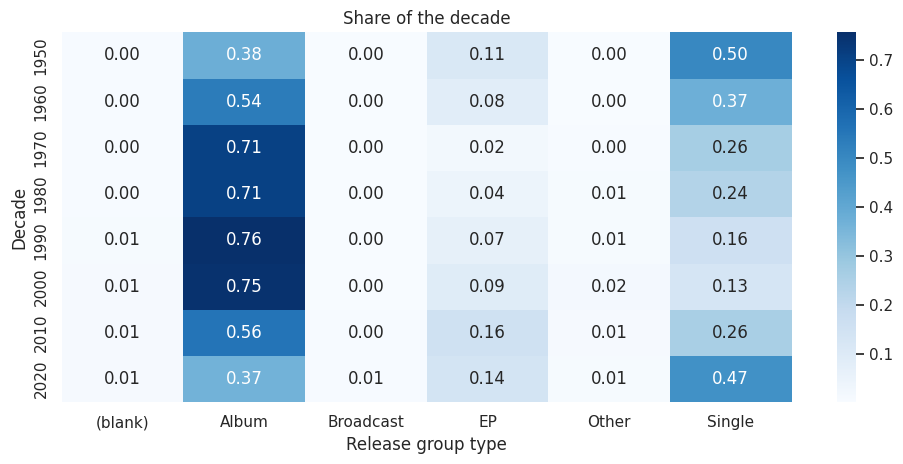

 year  releases
 1950      1266
 1980     14945
 2000     71366
 2010    120191
 2020    247204
 2024    259121
 2025    244193
 2026    154694


In [5]:
annual = window.groupby("year").size().rename("releases").reset_index()
by_type = (
    window.groupby(["year", "type_label"]).size().rename("releases").reset_index()
)
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(annual.year, annual.releases, color=PALETTE[0], lw=2)
ax.axvline(2026, color=PALETTE[1], ls="--", lw=1, label="2026 partial (dump 2026-10-24)")
park_legend(ax)
ax.set_xlabel("Year")
ax.set_ylabel("Official releases")
ax.set_title("Official releases per year, 1950-2026")
fig.tight_layout()
plt.show()

g = sns.relplot(
    data=by_type,
    x="year",
    y="releases",
    col="type_label",
    col_wrap=3,
    kind="line",
    height=2.5,
    aspect=1.35,
    color=PALETTE[0],
    facet_kws={"sharey": False},
)
g.set_axis_labels("Year", "Releases")
g.fig.suptitle("Official releases by type", y=1.02)
plt.show()

decade = (window.year // 10) * 10
share = pd.crosstab(decade, window.type_label, normalize="index")
fig, ax = plt.subplots(figsize=(10, 4.8))
sns.heatmap(share, annot=True, fmt=".2f", cmap="Blues", ax=ax)
ax.set_xlabel("Release group type")
ax.set_ylabel("Decade")
ax.set_title("Share of the decade")
fig.tight_layout()
plt.show()
print(annual.loc[annual.year.isin([1950, 1980, 2000, 2010, 2020, 2024, 2025, 2026])].to_string(index=False))

**Interpretation:** <br>
The official catalog is a long rise: 1,266 releases in 1950, 14,945 in 1980, 71,366 in 2000, 247,204 in 2020, and 259,121 in 2024. The dashed line marks 2026 as a partial year, so the drop after 2024 is the cutoff of the dump. The faceted lines show Album and Single carrying that rise. The decade heatmap is a within-decade share: albums are the majority of the 2010s, and singles are about half of both the 1950s and 2024.

# **5. Who and Where:** <a id="Who"></a>

In [6]:
per_artist = window.groupby("artist_mbid").size()
print("Releases per artist MBID in the window:")
print(per_artist.describe(percentiles=[0.5, 0.9, 0.99]).round(1).to_string())

top = (
    window.groupby(["artist_mbid", "artist_name"], dropna=False)
    .size()
    .reset_index(name="releases")
    .nlargest(8, "releases")
)
display(top.style.format({"releases": "{:,}"}).background_gradient(subset=["releases"], cmap="Blues"))
va_mbid = "89ad4ac3-39f7-470e-963a-56509c546377"
va_rows = int(window.artist_mbid.eq(va_mbid).sum())
assert va_rows == 259603
print("Various Artists MBID share of the window:", f"{va_rows / len(window):.1%}")

names = df.dropna(subset=["artist_name"]).groupby("artist_name").artist_mbid.nunique()
print("Names that map to more than one MBID:", int((names > 1).sum()))

Releases per artist MBID in the window:
count    881869.0
mean          5.8
std         277.6
min           1.0
50%           2.0
90%          10.0
99%          60.0
max      259603.0


,artist_mbid,artist_name,releases
474449,89ad4ac3-39f7-470e-963a-56509c546377,Various Artists,"259,603"
127212,24f1766e-9635-4d58-a4d4-9413f9f98a4c,Johann Sebastian Bach,"6,811"
108753,1f9df192-a621-4f54-8850-2c5373b7eac9,Ludwig van Beethoven,"6,661"
638389,b972f589-fb0e-474e-b64a-803b0364fa75,Wolfgang Amadeus Mozart,"6,484"
638854,b997d01a-dd9c-4b28-a99c-01732b08257d,Tôle-Ache,"3,280"
385804,70248960-cb53-4ea4-943a-edb18f7d336f,Bruce Springsteen,"3,045"
685270,c70d12a2-24fe-4f83-a6e6-57d84f8efb51,Johannes Brahms,"2,697"
858000,f91e3a88-24ee-4563-8963-fab73d2765ed,Franz Schubert,"2,614"


Various Artists MBID share of the window: 5.1%
Names that map to more than one MBID: 37130


**Interpretation:** <br>
The typical artist MBID has a short official list; the printed percentiles are that short list, and the table is the other end. One Various Artists MBID accounts for 259,603 window releases, about 5.1% of the window. Bach, Beethoven, and Mozart follow, which is the depth of official editions attached to one composer MBID. Names that map to more than one MBID are why the grain stays on `artist_mbid`.

# **6. What Describes the Growth:** <a id="Model"></a>

Spearman year vs annual releases, 1950-2025: 1.000 (p=5.099e-113)
Hold-out R2, log releases ~ year: 0.983
Log slope per year: 0.0716
Implied annual growth: 7.4%
Hold-out R2, releases ~ year: 0.684


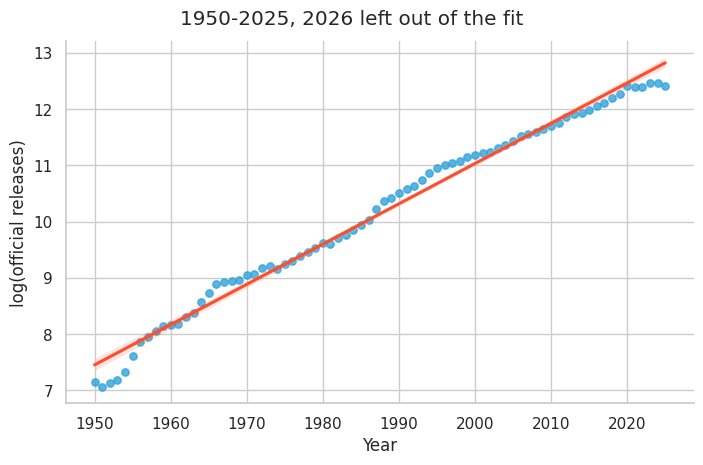

In [7]:
fit_years = annual.loc[annual.year < 2026].copy()
fit_years["log_releases"] = np.log(fit_years.releases)
assert fit_years.year.min() == 1950 and fit_years.year.max() == 2025
assert len(fit_years) == 76

rho, rho_p = stats.spearmanr(fit_years.year, fit_years.releases)
print(f"Spearman year vs annual releases, 1950-2025: {rho:.3f} (p={rho_p:.3e})")

X = fit_years[["year"]]
y_log = fit_years.log_releases
y_level = fit_years.releases
Xtr, Xte, ytr_log, yte_log, ytr_level, yte_level = train_test_split(
    X, y_log, y_level, test_size=0.25, random_state=7
)
log_model = LinearRegression().fit(Xtr, ytr_log)
level_model = LinearRegression().fit(Xtr, ytr_level)
print("Hold-out R2, log releases ~ year:", round(r2_score(yte_log, log_model.predict(Xte)), 3))
print("Log slope per year:", round(log_model.coef_[0], 4))
print("Implied annual growth:", f"{np.expm1(log_model.coef_[0]):.1%}")
print("Hold-out R2, releases ~ year:", round(r2_score(yte_level, level_model.predict(Xte)), 3))

g = sns.lmplot(
    data=fit_years,
    x="year",
    y="log_releases",
    height=4.5,
    aspect=1.6,
    scatter_kws={"s": 28, "color": PALETTE[0]},
    line_kws={"color": PALETTE[1]},
)
g.set_axis_labels("Year", "log(official releases)")
g.fig.suptitle("1950-2025, 2026 left out of the fit", y=1.03)
plt.show()

**Interpretation:** <br>
On 1950–2025, year and the annual release count rise together (Spearman 1.000). A hold-out linear model of log(releases) on year has R² 0.983 and slope 0.0716, about 7.4% more official releases per year. The same split on the raw count has hold-out R² 0.684, the weaker description, because the curve bends upward. 2026 stays on the earlier chart and stays out of this fit.

# **7. What It Means — Working Synthesis:** <a id="Synthesis"></a> <br>
The official MusicBrainz catalog in this file is 5,328,728 releases. The readable history is the 5,101,009 releases dated 1950–2026. That history is a steady multiplication of official releases, about 7.4% a year on the log fit through 2025 (hold-out R² 0.983). 2024 is the high point in the window, at 259,121 releases. 2026 is partial.

Album, Single, and EP are the catalog. Singles are about half of 2024; albums were the majority share of the 2010s. `XW` (worldwide) is the largest country code. Blank year, month, type, and country stay blank, and years outside 1950–2026 stay out of the charts, including the year 3036.

One Various Artists MBID is 5.1% of the window. The next catalogs are composer editions. Artist identity in this file is the MBID.

**Open follow-ups:** <br>
- A later export can finish 2026 and show whether the 2024 peak was the crest or just the last full year in this dump.
- Release-group relationships (which singles belong to which album) are a different table from this one-row-per-official-release list.